# Yield Model Audit — how good is the crop-yield model really?

The team's model-training notebook (`depiProject.ipynb`) reports a Random Forest yield model with
**test R² = 0.89**. Two choices in that pipeline can make the score look better than it is:

1. **The target is partly invented.** 3,730 missing `production` values are filled with the training
   median, then yield is computed from them.
2. **The target is clipped.** Yield above 5.27 is set to 5.27 (IQR rule) — about 15% of rows.
   The model is then scored against the clipped values, so it never has to predict the extreme ones.

A third choice affects what the test means:

3. **Random split across years.** The same district + crop appears in train and test, only in a
   different year — so the test asks "fill in a missing year", not "predict the future".

This notebook reproduces the team's setup exactly, then changes one thing at a time.
Same model (the tuned Random Forest) in every experiment.

In [1]:
import time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder, OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
warnings.filterwarnings("ignore")
SEED = 42
FIG = Path("outputs/figures"); TAB = Path("outputs/tables")
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(Path(kagglehub.dataset_download("abhinand05/crop-production-in-india")) / "crop_production.csv")
df = raw.copy()
df.columns = df.columns.str.strip().str.lower()
for c in ["state_name", "district_name", "season", "crop"]:
    df[c] = df[c].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
# Same exclusions as the team notebook
df = df[df["crop_year"] != 2015]
df = df[df["crop"].str.casefold() != "coconut"]
df = df[df["area"] >= 1.0].copy()
df["observed"] = df["production"].notna()
print("Rows:", len(df), "| missing production (target):", int((~df['observed']).sum()))

Rows: 243518 | missing production (target): 3686


In [2]:
FEATURES = ["state_name", "district_name", "crop_year", "season", "crop", "area"]
def make_pre():
    return ColumnTransformer([
        ("target", TargetEncoder(target_type="continuous", cv=5, shuffle=True, random_state=SEED),
         ["state_name", "district_name", "crop"]),
        ("season", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["season"]),
        ("numeric", StandardScaler(), ["area", "crop_year"])])
def make_rf():   # the team's tuned model
    return RandomForestRegressor(n_estimators=160, max_depth=18, min_samples_leaf=2,
                                 max_features=0.8, random_state=SEED, n_jobs=-1)
def fit_predict(Xtr, ytr, Xte):
    pre = make_pre(); rf = make_rf()
    rf.fit(pre.fit_transform(Xtr, ytr), ytr)
    return rf.predict(pre.transform(Xte))
def scores(y, p):
    return {"R2": r2_score(y, p), "MAE": mean_absolute_error(y, p), "RMSE": root_mean_squared_error(y, p)}
results = []

## 1. Reproduce the team's setup
Random 70/15/15 split (seed 42), missing production filled with the train median, area /
production / yield clipped with train IQR limits, RF scored on the clipped yield.

In [3]:
train, hold = train_test_split(df, test_size=0.30, random_state=SEED)
val, test = train_test_split(hold, test_size=0.50, random_state=SEED)
med = train["production"].median()

def team_prep(part, bounds=None):
    part = part.copy()
    part["yield_original"] = part["production"] / part["area"]      # NaN where production missing
    part["production"] = part["production"].fillna(med)
    part["yield"] = part["production"] / part["area"]
    return part
tr, te = team_prep(train), team_prep(test)
bounds = {}
for c in ["area", "production", "yield"]:
    q1, q3 = tr[c].quantile([0.25, 0.75]); iqr = q3 - q1
    bounds[c] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
clipped_share = (tr["yield"] > bounds["yield"][1]).mean()
for part in (tr, te):
    for c in ["area", "production", "yield"]:
        part[c] = part[c].clip(*bounds[c])
print(f"Train median production: {med:.0f} | yield clipped above {bounds['yield'][1]:.2f} "
      f"({clipped_share:.1%} of train rows)")

t0 = time.time()
pred_team = fit_predict(tr[FEATURES], tr["yield"], te[FEATURES])
print(f"Trained in {time.time()-t0:.0f}s")
results.append({"experiment": "A. Team setup (imputed + clipped target, random split)",
                "scored_on": "clipped yield, all test rows", **scores(te["yield"], pred_team)})
pd.DataFrame(results).round(3)

Train median production: 713 | yield clipped above 5.27 (15.4% of train rows)


Trained in 6s


,experiment,scored_on,R2,MAE,RMSE
0,"A. Team setup (imputed + clipped target, rando...","clipped yield, all test rows",0.891,0.315,0.578


## 2. Same predictions, scored against the real yield
Only rows where production was actually reported, compared with the **original, unclipped**
yield — what a farmer would actually see. (The team notebook computes this but never displays it.)

In [4]:
obs = te["observed"].values
y_true_orig = te.loc[obs, "yield_original"]
results.append({"experiment": "B. Same model, real target",
                "scored_on": "original yield, observed rows", **scores(y_true_orig, pred_team[obs])})
print(f"Original yield on observed test rows: median {y_true_orig.median():.2f}, "
      f"max {y_true_orig.max():,.0f}, share above clip limit {(y_true_orig > bounds['yield'][1]).mean():.1%}")
pd.DataFrame(results).round(3)

Original yield on observed test rows: median 1.00, max 74,500, share above clip limit 14.3%


,experiment,scored_on,R2,MAE,RMSE
0,"A. Team setup (imputed + clipped target, rando...","clipped yield, all test rows",0.891,0.315,0.578
1,"B. Same model, real target","original yield, observed rows",0.000,7.041,520.298


## 3. An honest target: no invented labels, log scale instead of clipping
- Drop the rows whose production is missing (we can't learn from a number we made up).
- Model **log(1 + yield)** instead of clipping: it tames the long tail *without* throwing information
  away, and every prediction maps back to a real yield.

In [5]:
obs_df = df[df["observed"]].copy()
obs_df["log_yield"] = np.log1p(obs_df["production"] / obs_df["area"])
o_train, o_hold = train_test_split(obs_df, test_size=0.30, random_state=SEED)
o_val, o_test = train_test_split(o_hold, test_size=0.50, random_state=SEED)
pred_log = fit_predict(o_train[FEATURES], o_train["log_yield"], o_test[FEATURES])
results.append({"experiment": "C. Observed rows, log target, random split",
                "scored_on": "log(1+yield)", **scores(o_test["log_yield"], pred_log)})
pd.DataFrame(results).round(3)

,experiment,scored_on,R2,MAE,RMSE
0,"A. Team setup (imputed + clipped target, rando...","clipped yield, all test rows",0.891,0.315,0.578
1,"B. Same model, real target","original yield, observed rows",0.000,7.041,520.298
2,"C. Observed rows, log target, random split",log(1+yield),0.934,0.136,0.233


## 4. Predicting the future: a time-based split
Train on 1997–2010, test on 2011–2014. This is the question a real yield model has to answer:
*given everything up to now, what will this district harvest next season?*

In [6]:
t_train = obs_df[obs_df["crop_year"] <= 2010]; t_test = obs_df[obs_df["crop_year"] >= 2011]
pred_time = fit_predict(t_train[FEATURES], t_train["log_yield"], t_test[FEATURES])
results.append({"experiment": "D. Observed rows, log target, train ≤2010 → test 2011–2014",
                "scored_on": "log(1+yield)", **scores(t_test["log_yield"], pred_time)})
print(f"Time split: {len(t_train):,} train rows, {len(t_test):,} test rows")
res = pd.DataFrame(results)
res.to_csv(TAB / "yield_model_audit.csv", index=False)
res.round(3)

Time split: 188,970 train rows, 50,862 test rows


,experiment,scored_on,R2,MAE,RMSE
0,"A. Team setup (imputed + clipped target, rando...","clipped yield, all test rows",0.891,0.315,0.578
1,"B. Same model, real target","original yield, observed rows",0.000,7.041,520.298
2,"C. Observed rows, log target, random split",log(1+yield),0.934,0.136,0.233
3,"D. Observed rows, log target, train ≤2010 → te...",log(1+yield),0.867,0.185,0.342


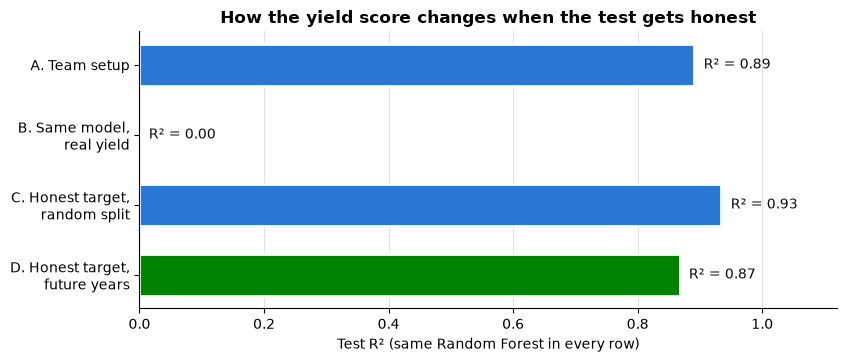

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
labels = ["A. Team setup", "B. Same model,\nreal yield", "C. Honest target,\nrandom split", "D. Honest target,\nfuture years"]
vals = res["R2"].values
colors = ["#2a78d6", "#c3c2b7", "#2a78d6", "#008300"]
ax.barh(labels[::-1], vals[::-1], color=colors[::-1], height=0.6, edgecolor="white", linewidth=2)
for y, v in enumerate(vals[::-1]):
    ax.text(v + 0.015, y, f"R² = {v:.2f}", va="center", ha="left", fontsize=10, color="#0b0b0b")
ax.set_xlim(0, 1.12); ax.set_xlabel("Test R² (same Random Forest in every row)")
ax.grid(axis="x", color="#e1e0d9"); ax.set_axisbelow(True)
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.set_title("How the yield score changes when the test gets honest", fontweight="bold")
fig.savefig(FIG / "20_yield_audit.png", dpi=160, bbox_inches="tight", facecolor="white")
plt.show()

## Conclusions

| Experiment (same tuned Random Forest) | Test R² |
|---|---|
| A. Team setup: imputed + clipped target, random split | 0.891 |
| B. Same predictions, scored on the real yield (observed rows) | 0.000 |
| C. Honest target (observed rows, log yield), random split | 0.934 |
| D. Honest target, train 1997–2010 → test 2011–2014 | 0.867 |

1. **The reported 0.89 measures agreement with capped numbers.** 15% of training yields were set to 5.27.
   Scored against the yields farmers actually reported, the same predictions explain none of the variance:
   a few extreme values (up to 74,500 per hectare, from mixed units and tiny plots) dominate the error.
2. **Modelled honestly the Random Forest is good.** Dropping the 3,686 invented targets and predicting
   log(1 + yield) instead of clipping gives R² 0.93.
3. **Predicting the future is harder, as it should be:** trained on 1997–2010, it explains 87% of the variance
   of 2011–2014 log yields. This is the number to present.
4. R² on log yield and R² on clipped yield are on different scales; compare experiments C and D with each other,
   not with A.